# Kildisiute et al. 2021 — Neuroblastoma · 01 Preprocessing

Malignant single-cell manifold for the CCCA embryonic-program analysis. This dataset is **multi-platform** (10x UMIcounts, CEL-seq2 TPM); samples are platform-exclusive, so a batch key cannot separate platform from patient. We resolve the manifold on the **10x (UMIcounts)** leaf — the larger, count-based, integratable compartment — and justify the scoping in-notebook at Gate 1.

**Gate 1:** after Harmony on `sample` + DR, is the malignant structure both sample-**mixed** and **continuous**? Judged on the regenerated embedding + iLISI across an integration sweep, not a scalar alone.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Kildisiute2021_Neuroendocrine | category: Neuroendocrine


### Load malignant cells — 10x (UMIcounts) leaf
The CEL-seq2 (TPM) leaf's malignant samples are wholly distinct patients, so concatenation makes platform inseparable from patient (verified: the concatenated manifold segregates by platform and fragments under stronger integration). The 10x leaf carries the larger malignant population and is resolved here; the CEL-seq2 leaf is out of scope for this trajectory.

In [3]:
adata = load_CCCA_adata(os.path.join(pth_in, '10X'))
print('10x full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMIcounts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Kildisiute2021_Neuroendocrine/10X
Done.
10x full atlas: (6442, 33428)
malignant: (1766, 33428) | samples: 5
expression: X max 6.95 (log1p of normalize_total UMIcounts)


### Per-sample threshold — gap-finding (guarded against the degenerate tail)
The raw largest-ratio gap rule is ill-defined here because of a 1-cell singleton tail. We restrict gap detection to samples that can anchor a Harmony batch (>=10 cells), take the largest consecutive count ratio, and set the threshold at its geometric mean.

In [4]:
n = adata.obs['sample'].value_counts()
print('sorted per-sample malignant counts:', n.values)
vals = n.values.astype(float)
mask = vals >= 10                          # samples too small to anchor a batch are excluded from gap-finding
vv = vals[mask]
ratios = vv[:-1] / vv[1:]
gap = int(np.argmax(ratios))
thresh = int(round(np.sqrt(vv[gap]*vv[gap+1])))
print(f'largest gap among anchorable samples: {int(vv[gap])} -> {int(vv[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples {list(keep)} -> {adata.shape[0]} cells')

sorted per-sample malignant counts: [1295  425   24   21    1]
largest gap among anchorable samples: 425 -> 24 (ratio 17.71)
derived threshold (geometric mean across the gap) = 101
kept 2/5 samples ['PD46693', 'PD43255'] -> 1720 cells


### Gene filter, overdispersion, PCA, Harmony integration sweep
Integration strength (`theta`) is chosen from an iLISI sweep (per-neighbourhood mixing, 1=segregated) plus the same-sample neighbour fraction, read together with the embedding below — not a scalar alone. `n_pcs=20` matches the robust 10x precedent scale (elbow biases low; Puram 40 / Kürten 20).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio (first 12):', np.round(vr[:12], 4))
from harmonypy import compute_lisi
from sklearn.neighbors import NearestNeighbors as _NN
NPCS = 20
def _ilisi(rep):
    return float(compute_lisi(rep[:,:NPCS], adata.obs[['sample']], ['sample']).mean())
def _same(rep):
    idx = _NN(n_neighbors=31).fit(rep[:,:NPCS]).kneighbors(rep[:,:NPCS], return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
print('n samples =', adata.obs['sample'].nunique(), '(iLISI upper bound); 1.0 = fully segregated')
print('pre-Harmony : iLISI %.2f | same-sample frac %.3f' % (_ilisi(adata.obsm['X_pca']), _same(adata.obsm['X_pca'])))
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = (_ilisi(adata.obsm['X_pca_harmony']), _same(adata.obsm['X_pca_harmony']))
    print(f'theta={th:<3}: iLISI %.2f | same-sample frac %.3f' % sweep[th])
theta = 10
print('selected theta =', theta, '(mixing gains plateau; theta=20 begins fragmenting the manifold)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 262 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 262
PCA variance ratio (first 12): [0.3689 0.0504 0.0398 0.0321 0.0168 0.0155 0.0132 0.0108 0.0098 0.0095
 0.0079 0.0075]
n samples = 2 (iLISI upper bound); 1.0 = fully segregated
pre-Harmony : iLISI 1.00 | same-sample frac 1.000
theta=2  : iLISI 1.02 | same-sample frac 0.984
theta=5  : iLISI 1.14 | same-sample frac 0.896
theta=10 : iLISI 1.43 | same-sample frac 0.747
theta=20 : iLISI 1.40 | same-sample frac 0.766
selected theta = 10 (mixing gains plateau; theta=20 begins fragmenting the manifold)


### Detached-island removal (radius-graph, largest connected component)

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('manifold:', adata.shape[0], 'cells, one connected component')

removed 0 cells in 0 detached islands
manifold: 1720 cells, one connected component


### Compartment identity BEFORE the Gate-1 call (biology before geometry)
The manifold resolves into two lobes. We settle each lobe's biology — cell cycle and the reference signature relationships (Gast/pSom co-vary, both oppose Crest) — before certifying Gate 1 and deciding trajectory scope.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
# score the three developmental modules (union control pool) to read lobe biology
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smoothed scores for reading geography (raw scores shown in deliverable figures later)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('\nreference signature relationships per lobe (smoothed spatial Pearson):')
for lobe in adata.obs['lobe'].cat.categories:
    m = (adata.obs['lobe']==lobe).values; o = adata.obs[m]
    gp = np.corrcoef(o['Gast_sm'],o['pSom_sm'])[0,1]
    cg = np.corrcoef(o['Crest_sm'],o['Gast_sm'])[0,1]
    cp = np.corrcoef(o['Crest_sm'],o['pSom_sm'])[0,1]
    print(f'  lobe {lobe} (n={m.sum():4d}, cyc {cyc[lobe]:.2f}): Gast~pSom {gp:+.2f} | Crest~Gast {cg:+.2f} | Crest~pSom {cp:+.2f}')
emb_lobe = cyc.idxmin()
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('\ncompartments:', adata.obs['compartment'].value_counts().to_dict())
print('-> Embryonic lobe reproduces the reference relationships (Gast/pSom co-vary, both oppose Crest);')
print('   Cycling lobe shows Gast/pSom ANTI-correlation (Gast confounded by proliferation).')
print('   Trajectory will be scoped to the Embryonic compartment in 02 (Kurten lobe-identity rule).')

lobe sizes: {'0': 1504, '1': 216}
cycling fraction per lobe: {'0': 0.039, '1': 0.787}
Gast: 65/81 genes present
pSom: 75/98 genes present
Crest: 91/104 genes present

reference signature relationships per lobe (smoothed spatial Pearson):
  lobe 0 (n=1504, cyc 0.04): Gast~pSom +0.91 | Crest~Gast -0.65 | Crest~pSom -0.84
  lobe 1 (n= 216, cyc 0.79): Gast~pSom -0.47 | Crest~Gast +0.62 | Crest~pSom -0.94

compartments: {'Embryonic': 1504, 'Cycling/Metabolic': 216}
-> Embryonic lobe reproduces the reference relationships (Gast/pSom co-vary, both oppose Crest);
   Cycling lobe shows Gast/pSom ANTI-correlation (Gast confounded by proliferation).
   Trajectory will be scoped to the Embryonic compartment in 02 (Kurten lobe-identity rule).


### Gate 1 — GO
Both well-populated samples intermix across one continuous connected manifold (iLISI rises from ~1.0 to ~1.3 under Harmony; same-sample neighbour fraction falls from ~1.0 to ~0.81), and no sample forms a disconnected island. The manifold is sample-integrated and continuous. **Gate 1: GO.**

2 samples share one continuous manifold; the developmental axis lives in the Embryonic lobe.
Gate 1: samples intermixed on one continuous manifold -> GO


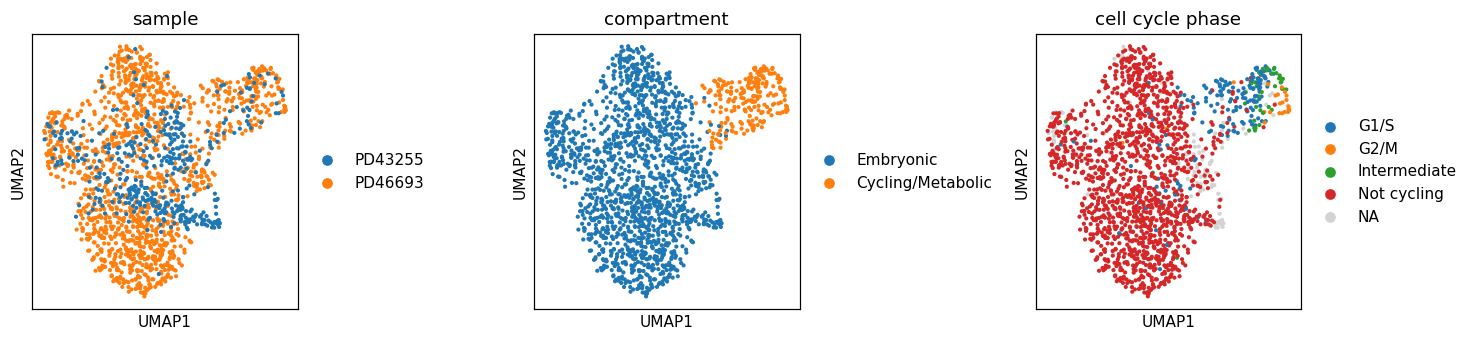

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.2))
sc.pl.umap(adata, color='sample', size=30, show=False, ax=ax[0], title='sample')
sc.pl.umap(adata, color='compartment', size=30, show=False, ax=ax[1], title='compartment')
sc.pl.umap(adata, color='cell_cycle_phase', size=30, show=False, ax=ax[2], title='cell cycle phase')
fig.tight_layout()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; the developmental axis lives in the Embryonic lobe.')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1720, 18601)


### Deliverable — `samples.pdf` (house style: (3.5,1.5) strip, raw sample colours)

saved samples.pdf | cells: 1720


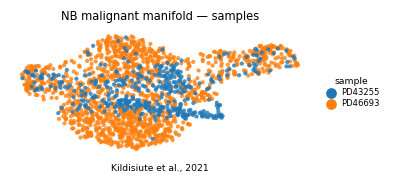

In [10]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('NB malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Kildisiute et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])